<a href="https://colab.research.google.com/github/alixhba20-oss/stochastic-differential-equations-monte-carlo/blob/main/01_SDE_Simulation_and_Convergence.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

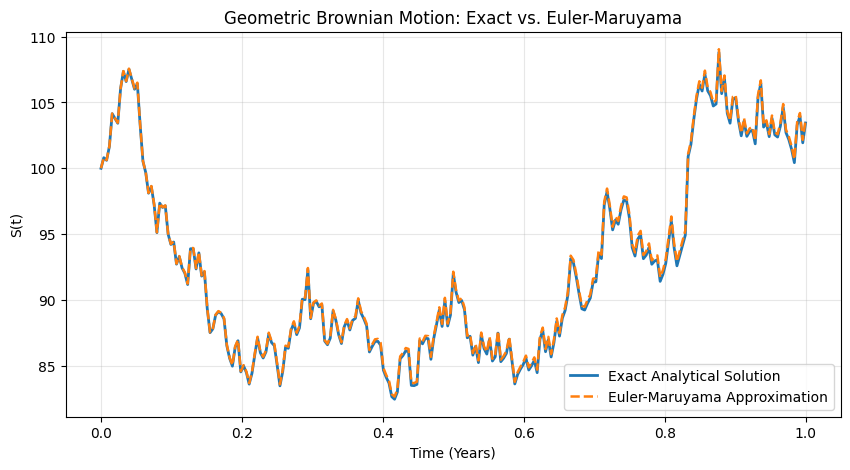

Maximum Absolute Error: 0.35488167977838714


In [4]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Parameters set karein
S0 = 100.0      # Initial value
mu = 0.08       # Drift (expected return)
sigma = 0.25    # Volatility (randomness)
T = 1.0         # Time horizon (1 year)
N = 252         # Number of time steps (daily steps)
dt = T / N

# 2. Brownian Motion (Wiener process) generate karein
np.random.seed(42)
t = np.linspace(0, T, N + 1)
dW = np.sqrt(dt) * np.random.randn(N)
W = np.concatenate(([0.0], np.cumsum(dW)))

# 3. Exact Analytical Solution
S_exact = S0 * np.exp((mu - 0.5 * sigma**2) * t + sigma * W)

# 4. Euler-Maruyama Numerical Approximation
S_euler = np.zeros(N + 1)
S_euler[0] = S0
for i in range(N):
    S_euler[i + 1] = S_euler[i] + mu * S_euler[i] * dt + sigma * S_euler[i] * dW[i]

# 5. Plot karke compare karein
plt.figure(figsize=(10, 5))
plt.plot(t, S_exact, label="Exact Analytical Solution", linewidth=2)
plt.plot(t, S_euler, "--", label="Euler-Maruyama Approximation", linewidth=1.8)
plt.title("Geometric Brownian Motion: Exact vs. Euler-Maruyama")
plt.xlabel("Time (Years)")
plt.ylabel("S(t)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print("Maximum Absolute Error:", np.max(np.abs(S_exact - S_euler)))

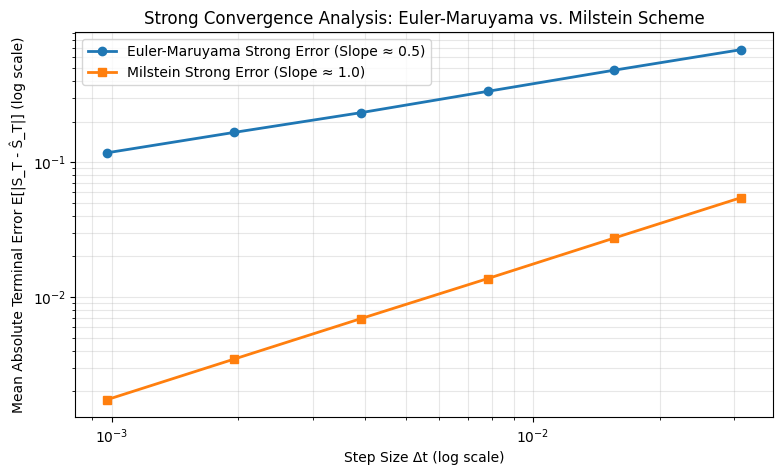

Estimated Euler-Maruyama Strong Order: 0.509 (Theoretical: 0.500)
Estimated Milstein Strong Order:       0.995 (Theoretical: 1.000)


In [5]:
# Cell 2: Strong Convergence Rate Comparison (Euler-Maruyama vs. Milstein)

def strong_convergence_study(S0=100.0, mu=0.08, sigma=0.25, T=1.0, n_paths=2000):
    rng = np.random.default_rng(42)
    N_fine = 2**10  # 1024 fine steps for reference Brownian motion
    dt_fine = T / N_fine

    # Fine Brownian increments for all paths
    dW_fine = np.sqrt(dt_fine) * rng.standard_normal((n_paths, N_fine))
    W_T = np.sum(dW_fine, axis=1)

    # Exact terminal value at T
    S_exact_T = S0 * np.exp((mu - 0.5 * sigma**2) * T + sigma * W_T)

    step_multipliers = [1, 2, 4, 8, 16, 32]
    dts = []
    euler_errors = []
    milstein_errors = []

    for m in step_multipliers:
        N_coarse = N_fine // m
        dt = T / N_coarse
        dts.append(dt)

        # Group fine Brownian increments into coarse increments
        dW = dW_fine.reshape(n_paths, N_coarse, m).sum(axis=2)

        S_em = np.full(n_paths, S0)
        S_mil = np.full(n_paths, S0)

        for i in range(N_coarse):
            S_em = S_em + mu * S_em * dt + sigma * S_em * dW[:, i]
            S_mil = (
                S_mil
                + mu * S_mil * dt
                + sigma * S_mil * dW[:, i]
                + 0.5 * (sigma**2) * S_mil * (dW[:, i]**2 - dt)
            )

        # Strong error: E[|S_exact(T) - S_approx(T)|]
        euler_errors.append(np.mean(np.abs(S_exact_T - S_em)))
        milstein_errors.append(np.mean(np.abs(S_exact_T - S_mil)))

    # Log-log convergence plot
    plt.figure(figsize=(9, 5))
    plt.loglog(dts, euler_errors, "o-", label="Euler-Maruyama Strong Error (Slope ≈ 0.5)", linewidth=2)
    plt.loglog(dts, milstein_errors, "s-", label="Milstein Strong Error (Slope ≈ 1.0)", linewidth=2)
    plt.title("Strong Convergence Analysis: Euler-Maruyama vs. Milstein Scheme")
    plt.xlabel("Step Size Δt (log scale)")
    plt.ylabel("Mean Absolute Terminal Error E[|S_T - Ŝ_T|] (log scale)")
    plt.legend()
    plt.grid(True, which="both", alpha=0.3)
    plt.show()

    # Empirical convergence orders (slopes in log-log space)
    em_slope = np.polyfit(np.log(dts), np.log(euler_errors), 1)[0]
    mil_slope = np.polyfit(np.log(dts), np.log(milstein_errors), 1)[0]
    print(f"Estimated Euler-Maruyama Strong Order: {em_slope:.3f} (Theoretical: 0.500)")
    print(f"Estimated Milstein Strong Order:       {mil_slope:.3f} (Theoretical: 1.000)")

strong_convergence_study()

True mu: 0.1000 | MLE mu_hat:    0.3502
True sigma: 0.2200 | MLE sigma_hat: 0.2151
Mean Projected Price (T=1.0y): 197.61
95% Confidence Interval (Terminal): [127.40, 291.39]
95% Monte Carlo VaR (Max Expected Loss): 2.18%


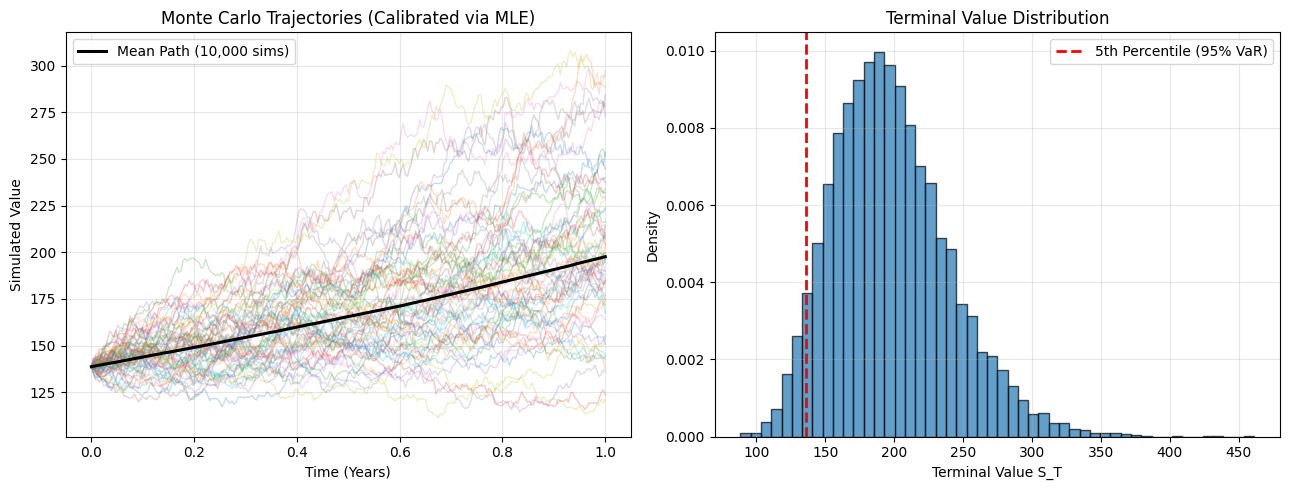

In [6]:
# Cell 3: Parameter Estimation (MLE) & 10,000 Monte Carlo Paths + 95% Value-at-Risk (VaR)

def mle_and_monte_carlo(true_S0=100.0, true_mu=0.10, true_sigma=0.22, T=1.0, N_obs=252, n_mc=10000):
    rng = np.random.default_rng(123)
    dt = T / N_obs

    # 1. Generate one observed path from true parameters
    dW_obs = np.sqrt(dt) * rng.standard_normal(N_obs)
    W_obs = np.concatenate(([0.0], np.cumsum(dW_obs)))
    t_obs = np.linspace(0.0, T, N_obs + 1)
    S_obs = true_S0 * np.exp((true_mu - 0.5 * true_sigma**2) * t_obs + true_sigma * W_obs)

    # 2. Maximum Likelihood Estimation (MLE) on log-returns
    log_returns = np.diff(np.log(S_obs))
    r_bar = np.mean(log_returns)
    sigma_hat = np.sqrt(np.mean((log_returns - r_bar) ** 2) / dt)
    mu_hat = (r_bar / dt) + 0.5 * (sigma_hat ** 2)

    print(f"True mu: {true_mu:.4f} | MLE mu_hat:    {mu_hat:.4f}")
    print(f"True sigma: {true_sigma:.4f} | MLE sigma_hat: {sigma_hat:.4f}")

    # 3. Simulate 10,000 Monte Carlo paths using estimated parameters
    z_mc = rng.standard_normal((n_mc, N_obs))
    W_mc = np.concatenate([np.zeros((n_mc, 1)), np.cumsum(np.sqrt(dt) * z_mc, axis=1)], axis=1)
    S_mc = S_obs[-1] * np.exp((mu_hat - 0.5 * sigma_hat**2) * t_obs + sigma_hat * W_mc)

    # 4. Terminal distribution & 95% Monte Carlo Value-at-Risk (1-year horizon)
    terminal_prices = S_mc[:, -1]
    pct_returns = (terminal_prices - S_obs[-1]) / S_obs[-1]
    var_95_loss = -np.percentile(pct_returns, 5) * 100  # in %

    print(f"Mean Projected Price (T={T}y): {np.mean(terminal_prices):.2f}")
    print(f"95% Confidence Interval (Terminal): [{np.percentile(terminal_prices, 2.5):.2f}, {np.percentile(terminal_prices, 97.5):.2f}]")
    print(f"95% Monte Carlo VaR (Max Expected Loss): {var_95_loss:.2f}%")

    # 5. Plot sample Monte Carlo paths + terminal histogram
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

    for idx in range(60):
        ax1.plot(t_obs, S_mc[idx], alpha=0.25, linewidth=1)
    ax1.plot(t_obs, np.mean(S_mc, axis=0), color="black", linewidth=2.2, label="Mean Path (10,000 sims)")
    ax1.set_title("Monte Carlo Trajectories (Calibrated via MLE)")
    ax1.set_xlabel("Time (Years)")
    ax1.set_ylabel("Simulated Value")
    ax1.legend()
    ax1.grid(True, alpha=0.3)

    ax2.hist(terminal_prices, bins=50, density=True, alpha=0.7, edgecolor="black")
    ax2.axvline(np.percentile(terminal_prices, 5), color="red", linestyle="--", linewidth=2, label="5th Percentile (95% VaR)")
    ax2.set_title("Terminal Value Distribution")
    ax2.set_xlabel("Terminal Value S_T")
    ax2.set_ylabel("Density")
    ax2.legend()
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

mle_and_monte_carlo()